In [2]:
# Step 1: Import required libraries
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [3]:
# Step 1: Load training and testing datasets
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")
print("Training Dataset Shape:", train_data.shape)
print("Testing Dataset Shape:", test_data.shape)


Training Dataset Shape: (27455, 785)
Testing Dataset Shape: (7172, 785)


In [4]:
# Step 3: Separate features and labels
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

In [5]:
# Step 4: Convert labels into 24 consecutive classes
classes = np.sort(np.unique(y_train))
label_map = {label: i for i, label in enumerate(classes)}

y_train = np.array([label_map[label] for label in y_train])
y_test = np.array([label_map[label] for label in y_test])

In [6]:

# Step 5: Normalize pixel values
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0


In [7]:
# Step 6: Flatten images (28 x 28 = 784)
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

In [8]:
# Step 7: Split training dataset for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [9]:
# Step 8: Construct Feedforward Neural Network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(24, activation='softmax')
])

In [10]:
# Step 9: Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [11]:
# Step 10: Display model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 24)                  │           1,560 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 243,672 (951.84 KB)

 Trainable params: 243,672 (951.84 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Step 11: Train the model
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=128,
    validation_data=(X_val, y_val)
)

Epoch 1/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.2710 - loss: 2.4042 - val_accuracy: 0.4571 - val_loss: 1.7412
Epoch 2/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5524 - loss: 1.4481 - val_accuracy: 0.5955 - val_loss: 1.2259
Epoch 3/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6413 - loss: 1.1089 - val_accuracy: 0.6995 - val_loss: 0.9492
Epoch 4/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7413 - loss: 0.8234 - val_accuracy: 0.7520 - val_loss: 0.7831
Epoch 5/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7886 - loss: 0.6745 - val_accuracy: 0.8243 - val_loss: 0.5685
Epoch 6/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8368 - loss: 0.5245 - val_accuracy: 0.8379 - val_loss: 0.5088
Epoch 7/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8748 - loss: 0.4076 - val_accuracy: 0.8578 - val_loss: 0.4354
Epoch 8/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9081 - loss: 0.3168 - val_accuracy: 0.

In [13]:
# Step 12: Display training accuracy
training_accuracy = history.history['accuracy'][-1]

print("\nTraining Accuracy: {:.2f}%".format(
    training_accuracy * 100
))


Training Accuracy: 99.43%


In [14]:
# Step 13: Evaluate model using testing dataset
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("\nTesting Accuracy: {:.2f}%".format(
    test_accuracy * 100
))
print("Testing Loss:", test_loss)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7528 - loss: 1.0879

Testing Accuracy: 75.28%
Testing Loss: 1.0879048109054565


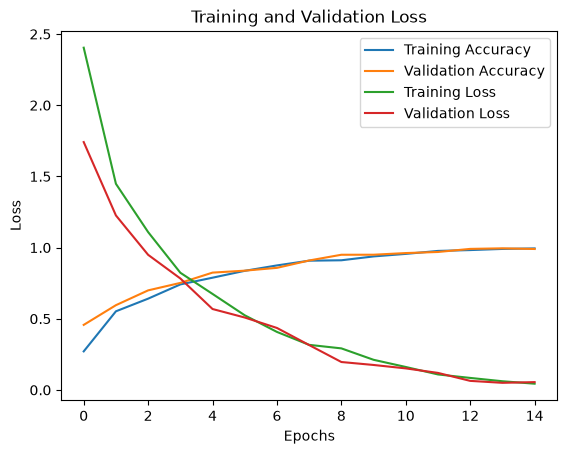

In [15]:
# Step 14: Plot accuracy and loss graphs
# plt.figure(figsize=(12, 5))

# Accuracy graph
# plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
# plt.grid(True)

# Loss graph
# plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
# plt.grid(True)

# plt.tight_layout()
plt.show()


In [ ]:
# 2. Construct a Feedforward Neural Network for Sign Language alphabet
# recognition. Train the model using the training dataset and evaluate it
# using the testing dataset. Display the training accuracy, testing accuracy
# and loss graph.